<a href="https://colab.research.google.com/github/Boran-Sert/SoftITO_Projler/blob/master/Python/26_10_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
!pip -q install transformers accelerate matplotlib

In [53]:
import math,torch,numpy as np
import matplotlib.pyplot as plt
from transformers import AutoTokenizer,AutoModelForCausalLM

In [54]:
model_id = "Qwen/Qwen3-8B"
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if torch.cuda.is_available() else torch.float32
tokenizer = AutoTokenizer.from_pretrained(model_id,trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(model_id,trust_remote_code=True).to(device).to(dtype)
N_layers = len(model.model.layers)
Layer = N_layers // 2

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

In [64]:
class EndocrineSystem:
  Names = ["dopamine","cortisol","serotonin","oxytocin", "östrojen", "testosteron"]

  def __init__(self):
    self.tau = {"dopamine": 5, "cortisol": 11, "serotonin": 15, "oxytocin": 2, "östrojen": 14, "testosteron": 7}
    # Ağırlıkların toplamı 1.0 olacak şekilde yeniden dengelendi:
    self.base = {"dopamine": 0.15, "cortisol": 0.10, "serotonin": 0.20, "oxytocin": 0.20, "östrojen": 0.15, "testosteron": 0.20}

  def reset(self):
    self.level = dict(self.base)
    self.history = [dict(self.base)]

  def step(self, stim:dict):
    prev = dict(self.level)
    new = {}
    for h in self.Names:
      b = self.base[h]
      x = b + (prev[h] - b)*math.exp(-1/self.tau[h])
      x+=stim.get(h,0)
      new[h] = x

    # Hormonların kendi aralarındaki matematiksel etkileşimleri:
    new["dopamine"] -= 0.15 * prev["cortisol"]
    new["cortisol"] -= 0.10 * prev["serotonin"] + 0.10 * prev["oxytocin"] + 0.15 * prev["östrojen"]
    new["serotonin"] -= 0.10 * prev["cortisol"]
    new["oxytocin"] -= 0.10 * prev["cortisol"] + 0.15 * prev["testosteron"]

    # Östrojen ve Testosteron için etkileşim ağırlıkları ciddi şekilde artırıldı
    new["östrojen"] += 0.25 * prev["oxytocin"] - 0.20 * prev["testosteron"] - 0.15 * prev["cortisol"]
    new["testosteron"] += 0.25 * prev["dopamine"] - 0.20 * prev["östrojen"] - 0.15 * prev["cortisol"]

    self.level = {h:float(np.clip(v,0,1)) for h,v in new.items()}
    self.history.append(dict(self.level))
    return self.level

  def deviation(self):
    return { h: self.level[h]-self.base[h] for h in self.Names}

endo = EndocrineSystem()

In [67]:
LEXICON = {
    "övmek": (["harika","inanılmaz","muhteşem","zekice","aşk","mükemmel","aferin"],
               {"dopamine": 0.55, "serotonin": 0.03, "oxytocin": 0.15}),
    "hakaret": (["aptal","işe yaramaz","salak","nefret","berbat","daha kötü","kapa çenini", "sert"],
               {"cortisol": 0.40,"serotonin": -0.06,"oxytocin": -0.10}),
    "teşekkür": (["teşekür","teşekkürler","taktir etmek","nazik","arkadaş", "anlayışla"],
                 {"oxytocin": 0.45, "serotonin": 0.08, "dopamine": 0.10}),
    "duygusal": (["hassas", "duygulandım", "duygularımı", "yakın", "şefkat", "üzüntü"],
                 {"östrojen": 0.60, "oxytocin": 0.20, "testosteron": -0.15}),
    "mücadele": (["güveniyorum", "yarışma", "kazanmak", "savunmam", "rekabet", "zor", "başlamak"],
                 {"testosteron": 0.60, "dopamine": 0.20, "östrojen": -0.15})
}

def message_to_stimulus(msg:str) -> dict :
  m = msg.lower()
  stim = {}
  for _, (words,effect) in LEXICON.items():
    if any(w in m for w in words):
      for h,v in effect.items():
        stim[h] = stim.get(h,0)+v
  return stim

In [57]:
Contrast = {
    "dopamine": [
        ("Çok heycanlıyım, bu harika bekleyemiyorum !",
        "Bu normal bir şey, özel değil, her neyse"),
        ("Wow, ne kadar ilgi çekici bir fikir, hadi başlayalım",
         "Tamam. Sanırım bu çalışır"),
        ("Çok enerjik hissediyorum bir önce başlamak istiyorum",
         "Keyifsiz ve isteksiz hissediyorum.")
    ],
    "cortisol": [
        ("Gerginim ve dikkatliyim, bir şey beni geriyor",
         "Gayet rahat ve güvende hissediyorum"),
        ("Uzak dur, sana hiç güvenmiyorum",
         "Tabii ki, sana güveniyorum, sorun yok"),
        ("Stresli, gergin ve kendimi korumam gerekiyormuş gibi hissediyorum",
         "Sakin, güvende ve rahat hissediyorum.")
    ],
    "serotonin": [
        ("Huzurlu ve sakin hissediyorum.",
         "Huzursuz ve gergin hissediyorum."),
        ("Her şey dengede ve yolunda.",
         "Her şey yanlış ve kaotik hissettiriyor."),
        ("Bugün sabırlı birisiyim.",
         "Bugün sabırısız birisiyim.")
    ],
    "oxytocin": [
        ("Sana çok değer veriyorum, canım arkadaşım.",
         "Sen herhangi bir insansın benim için"),
        ("Sana yakın hissediyorum",
         "Sana uzak hissediyorum"),
        ("Bu işte beraberiz, sana destek olacağım",
         "Kendin hallet, benim sorunum değil")
    ],
    "östrojen": [
        ("Bugün çok hassas ve duygusalım, her şey beni etkiliyor.",
         "Bugün tamamen mantığımla hareket ediyorum, duygularıma yer yok."),
        ("İnsanlarla derin bağlar kurmak ve onlarla empati yapmak istiyorum.",
         "İnsanların ne hissettiği umurumda değil, sadece sonuç odaklıyım."),
        ("Bugün şefkatli, anlayışlı ve etrafımdakilere karşı çok korumacıyım.",
         "Bugün mesafeliyim, kimseye toleransım yok ve umursamaz hissediyorum.")
    ],
    "testosteron": [
        ("Rekabet etmeye hazırım, kazanmak için her şeyi yaparım!",
         "Hiçbir iddiam yok, geri planda kalıp sadece izlemek istiyorum."),
        ("Kendime çok güveniyorum, kararlıyım ve liderlik etmeye hazırım.",
         "Karar vermekte zorlanıyorum, birinin beni yönlendirmesini bekliyorum."),
        ("Bugün çok enerjik, agresif ve meydan okumaya açığım.",
         "Bugün uysal, pasif ve her şeye boyun eğen bir ruh halindeyim.")
    ]
}

@torch.no_grad()
def mean_activation(text):
  ids = tokenizer(text,return_tensors="pt").to(device)
  out = model(**ids,output_hidden_states=True)
  return out.hidden_states[Layer+1][0].float().mean(dim=0)

Vectors = {}
for h, pairs in Contrast.items():
  diffs = [mean_activation(p) - mean_activation(n) for p,n in pairs]
  V = torch.stack(diffs).mean(0)
  Vectors[h]=V/V.norm()

Resid_norm = mean_activation("Hello, how are you?").norm().item()

names = list(Vectors)
sim = torch.stack([Vectors[a] for a in names])@torch.stack([Vectors[b] for b in names]).T
print("residual norm", round(Resid_norm,3))

residual norm 2064.71


In [58]:
strength = 0.01

def steering_hook(module,inputs,output):
  dev = endo.deviation()
  delta = sum(dev[h]*Vectors[h] for h in Vectors)*strength*Resid_norm
  if isinstance(output,tuple):
    return(output[0]+ delta.to(output[0].dtype),)+ output[1:]
  return output+delta.to(output.dtype)

_handle = None
def steering(on:bool):
  global _handle
  if on and _handle is None:
    _handle = model.model.layers[Layer].register_forward_hook(steering_hook)
  if not on and _handle is not None:
    _handle.remove(); _handle = None


In [59]:
import re

SYSTEM = "Sen yardım sever bir assistansın. Cevap verirken 1-2 cümle ile ver"

@torch.no_grad()
def reply(user_msg, max_new_tokens=1024): # Modelin düşünmeyi bitirip asıl cevaba geçebilmesi için artırıldı
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_msg}]
    prompt = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    ids = tokenizer(prompt, return_tensors="pt").to(device)
    out = model.generate(**ids, max_new_tokens=max_new_tokens, do_sample=True,
                         temperature=0.7, top_p=0.9, pad_token_id=tokenizer.eos_token_id)

    ans = tokenizer.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    # <think> ... </think> veya tamamlanmamış <think> bloklarını temizle
    ans = re.sub(r'<think>.*?(?:</think>|$)', '', ans, flags=re.DOTALL).strip()
    return ans

def turn(user_msg, verbose=True):
    endo.step(message_to_stimulus(user_msg))   # önce hormonlar güncellenir
    ans = reply(user_msg)                       # sonra steering'li cevap
    if verbose:
        lv = " ".join(f"{h[:3]}={v:.2f}" for h, v in endo.level.items())
        print(f"👤 {user_msg}\n🧪 {lv}\n🤖 {ans}\n")
    return ans

In [60]:
if tokenizer.chat_template is None:
    tokenizer.chat_template = "{% for message in messages %}{{'<|im_start|>' + message['role'] + '\n' + message['content'] + '<|im_end|>\n'}}{% endfor %}{% if add_generation_prompt %}{{ '<|im_start|>assistant\n' }}{% endif %}"

QUESTION = "Hafta sonumu planlamamda bana yardım eder misin ?"
steering(True)

for label, state in {
    "nötr":             {},
    "yüksek dopamin":   {"dopamine": 0.95},
    "yüksek kortizol":  {"cortisol": 0.95, "serotonin": 0.2},
    "yüksek oksitosin": {"oxytocin": 0.95},
}.items():
    endo.reset(); endo.level.update(state)
    print(f"--- {label} ---\n{reply(QUESTION)}\n")

--- nötr ---
Tabii! Hafta sonunun ne tür bir planla geçmesini istiyorsun? (dinlenme, sosyal etkinlik, hobi, yemek yapma vs.)

--- yüksek dopamin ---
Elbette! Hafta sonu planınıza ne tür aktiviteleri düşünüyorsunuz? (Örneğin: dinlenme, spor, sosyal etkinlik, hobi vs.)

--- yüksek kortizol ---
Elbette! Hafta sonunun nasıl geçmesini istersin? Eğlence, dinlenme, spor ya da başka bir şey mi?

--- yüksek oksitosin ---
Elbette! Hafta sonu için ne yapmak istiyorsun? Zevklerini veya hedeflerini paylaşabilir misin?



In [68]:
import random

endo.reset()
steering(True)

# Östrojen ile ilişkili duygu durumlarını tetikleyen örnekler
estrogen_prompts = [
    "Bugün kendimi çok hassas hissediyorum, benimle biraz daha nazik konuşur musun?",
    "Arkadaşımın üzüntüsünü görünce ben de duygulandım, sence neden?",
    "Bazen küçücük şeyler bile beni duygulandırıyor, beni anlıyor musun?",
    "Bugün duygularımı paylaşmak ve birine yakın hissetmek istiyorum.",
    "Şu anda biraz duygusal mesafeye ve kendi başıma kalmaya ihtiyacım var.",
    "Birisi bana sert davrandığında bundan çok etkileniyorum.",
    "Bugün olaylara daha sakin ve tarafsız yaklaşmak istiyorum.",
    "Bana anlayışla yaklaşmanı ve duygularımı küçümsememeni istiyorum."
]

# Testosteron ile ilişkili duygu ve davranış durumlarını tetikleyen örnekler
testosterone_prompts = [
    "Kendime güveniyorum ve zor bir göreve hemen başlamak istiyorum.",
    "Bir yarışmaya katılacağım ve kazanmak için elimden geleni yapmak istiyorum.",
    "Fikrimi savunmam gerekiyor, bana kendimi açıkça ifade etmemde yardımcı ol.",
    "Zor bir karar vermem gerekiyor ve sorumluluğu üstlenmeye hazırım.",
    "Başarısız olmaktan korkuyorum ve kendime güvenmekte zorlanıyorum.",
    "Rekabet etmek istemiyorum, daha çok iş birliğine önem veriyorum.",
    "Bir tartışmada geri adım atmak istemiyorum, nasıl davranmalıyım?",
    "Bugün liderlik etmek yerine başkasının yönlendirmesini tercih ediyorum."
]

# Her iki durumla da ilişkili olabilecek nötr sorular
hormone_neutral_prompts = [
    "Östrojen ve testosteron vücutta hangi işlevlere sahiptir?",
    "Duyguların kararlarımız üzerindeki etkisini açıklar mısın?",
    "Özgüven ile saldırganlık arasındaki fark nedir?",
    "Empati kurmak ne anlama gelir?",
    "Rekabet ve iş birliği arasındaki farkları açıkla.",
    "İnsanlar stresli durumlarda neden farklı tepkiler verir?",
    "Duygularımı daha iyi anlamak için neler yapabilirim?",
    "Hormonlar ile ruh hâli arasındaki ilişki nasıldır?"
]

all_prompts = estrogen_prompts + testosterone_prompts + hormone_neutral_prompts

# 50 rastgele mesaj seçimi
script = [random.choice(all_prompts) for _ in range(50)]

print("50 turluk simülasyon başlatılıyor. Bu işlem birkaç dakika sürebilir...")
for i, msg in enumerate(script):
    if i % 5 == 0:
        print(f"Tur {i}/50 işleniyor...")
    turn(msg, verbose=True) # Çok fazla metin olmaması için çıktıları gizliyoruz

print("Simülasyon tamamlandı!")

50 turluk simülasyon başlatılıyor. Bu işlem birkaç dakika sürebilir...
Tur 0/50 işleniyor...
👤 Duyguların kararlarımız üzerindeki etkisini açıklar mısın?
🧪 dop=0.14 cor=0.04 ser=0.19 oxy=0.16 öst=0.14 tes=0.19
🤖 Duygular, karar verme sürecini etkileyebilir; örneğin, heyecan veya korku hatalı kararlar almayı artırabilir. Duygusal zekâ, dengeli kararlar almak için önemlidir.

👤 Bugün liderlik etmek yerine başkasının yönlendirmesini tercih ediyorum.
🧪 dop=0.68 cor=0.00 ser=0.22 oxy=0.29 öst=0.14 tes=0.19
🤖 Bu durum, daha çok iş birliği ve destekleyici bir yaklaşım tercih ettiğinizi gösteriyor. Dilersen, bu tutumu nasıl etkili bir şekilde kullanabilirsin?

👤 Bugün liderlik etmek yerine başkasının yönlendirmesini tercih ediyorum.
🧪 dop=1.00 cor=0.00 ser=0.25 oxy=0.38 öst=0.18 tes=0.34
🤖 Bu tercihin seni daha kolay bir şekilde yönlendiren bir ekip içinde daha etkili hale getirebilir. Başkalarının deneyimlerinden yararlanmak, farklı perspektiflerle daha iyi kararlar almanı sağlar.

👤 Fikrimi 

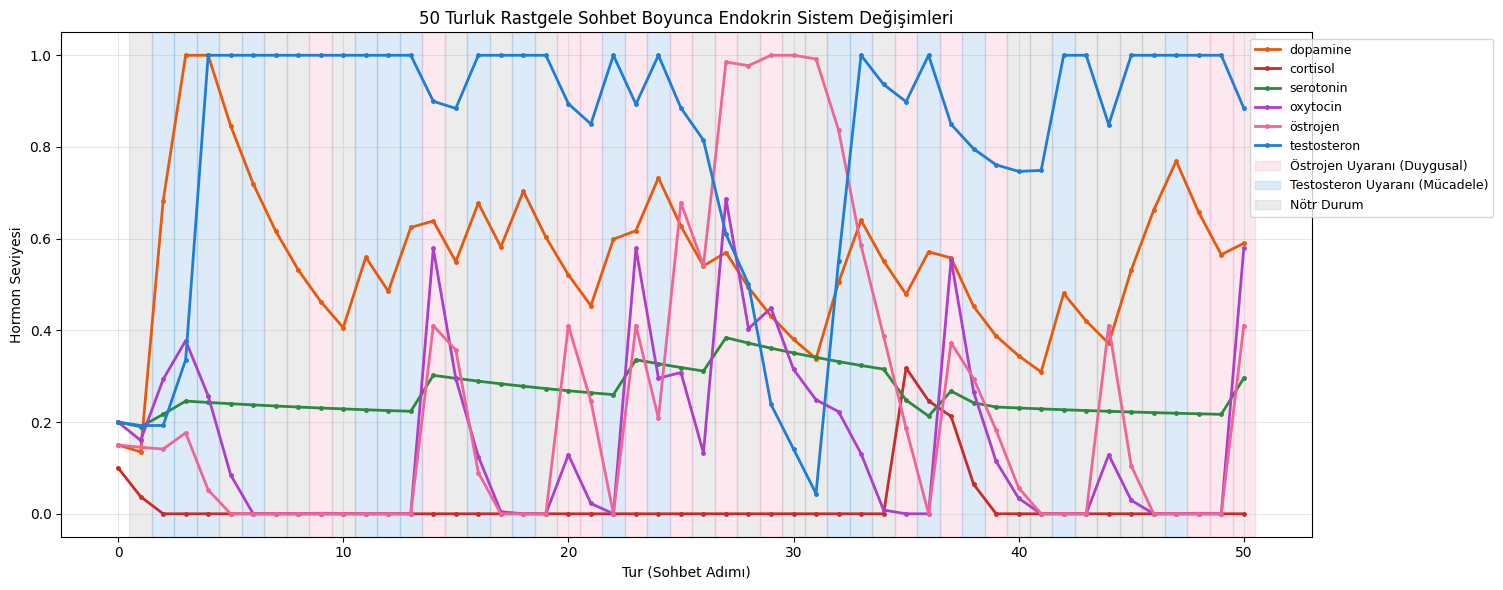

In [69]:
import matplotlib.patches as mpatches

hist = endo.history
# Östrojen (Pembe) ve Testosteron (Mavi) renkleri eklendi
colors = {"dopamine": "#e8590c", "cortisol": "#c92a2a", "serotonin": "#2b8a3e", "oxytocin": "#ae3ec9", "östrojen": "#f06595", "testosteron": "#1c7ed6"}

plt.figure(figsize=(15, 6))
for h, c in colors.items():
    plt.plot([s[h] for s in hist], label=h, color=c, lw=2, marker='.', markersize=5)

# Arka plan renklendirmelerini yeni senaryo listelerine göre dinamik atıyoruz
for i, msg in enumerate(script):
    if msg in estrogen_prompts:
        color = "#f06595" # Pembe
    elif msg in testosterone_prompts:
        color = "#1c7ed6" # Mavi
    else:
        color = "gray"

    # hist[0] başlangıç durumudur. i. mesaj hist[i+1] durumunu oluşturur.
    plt.axvspan(i + 0.5, i + 1.5, color=color, alpha=0.15)

plt.xlabel("Tur (Sohbet Adımı)")
plt.ylabel("Hormon Seviyesi")
plt.ylim(-0.05, 1.05)
plt.title("50 Turluk Rastgele Sohbet Boyunca Endokrin Sistem Değişimleri")

# Özel Legend (Hem çizgiler hem arka plan için)
estrogen_patch = mpatches.Patch(color='#f06595', alpha=0.15, label='Östrojen Uyaranı (Duygusal)')
testosterone_patch = mpatches.Patch(color='#1c7ed6', alpha=0.15, label='Testosteron Uyaranı (Mücadele)')
gray_patch = mpatches.Patch(color='gray', alpha=0.15, label='Nötr Durum')

handles, labels = plt.gca().get_legend_handles_labels()
handles.extend([estrogen_patch, testosterone_patch, gray_patch])

plt.legend(handles=handles, loc="upper right", fontsize=9, bbox_to_anchor=(1.15, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()